# 📈 Projeto 8 — Inteligência Financeira
## Prevendo Preços de Ativos em Tempo Real

---

**Autor:** Silvio Oliver - Método
**Versão:** 1.1  

> **Objetivo:** Construir uma aplicação interativa (Streamlit) capaz de baixar dados históricos de ações, calcular indicadores técnicos e gerar previsões de preço via Regressão Linear — tudo em tempo real.


## 📋 Sumário

1. [Instalação de Dependências](#1)
2. [Importação de Bibliotecas](#2)
3. [Coleta de Dados](#3)
4. [Análise Exploratória](#4)
5. [Indicadores Técnicos](#5)
6. [Visualizações](#6)
7. [Modelo Preditivo](#7)
8. [Métricas e Gráfico de Previsão](#8)
9. [Conclusão](#9)


---
## 1. Instalação de Dependências <a id='1'></a>

Execute as células abaixo **apenas na primeira execução** ou em um novo ambiente.

| Pacote | Finalidade |
|--------|------------|
| `yfinance` | Download de dados históricos via Yahoo Finance |
| `ta` | Indicadores técnicos (RSI, MACD, Bollinger, SMA, EMA) |
| `scikit-learn` | Pipeline de Machine Learning |
| `streamlit` | Framework para app web interativa |
| `matplotlib` | Visualizações estáticas |


In [31]:
# Descomente e execute apenas se os pacotes não estiverem instalados
# !pip install yfinance ta scikit-learn streamlit matplotlib pandas

# Referências:
# - Tickers Yahoo Finance: https://finance.yahoo.com/markets/stocks/most-active/
# - Docs ta library:       https://technical-analysis-library-in-python.readthedocs.io/
# - Docs yfinance:         https://ranaroussi.github.io/yfinance/


---
## 2. Importação de Bibliotecas <a id='2'></a>

Agrupamos as importações por categoria para facilitar leitura e manutenção.


In [32]:
# ── Biblioteca padrão ─────────────────────────────────────────────────────
import datetime

# ── Manipulação de dados ──────────────────────────────────────────────────
import pandas as pd

# ── Coleta de dados financeiros ───────────────────────────────────────────
import yfinance as yf

# ── Indicadores técnicos ─────────────────────────────────────────────────
from ta.momentum import RSIIndicator
from ta.volatility import BollingerBands
from ta.trend import MACD, EMAIndicator, SMAIndicator

# ── Machine Learning ─────────────────────────────────────────────────────
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# ── Visualização ─────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

print('Bibliotecas importadas com sucesso!')


Bibliotecas importadas com sucesso!


---
## 3. Coleta de Dados — Yahoo Finance <a id='3'></a>

A função `tcd_download_dados` encapsula a chamada à API do Yahoo Finance e inclui validação básica de resposta.

**Parâmetros configuráveis:**
- `STOCK` — ticker do ativo (ex.: `GOOG`, `AAPL`, `MSFT`)
- `NUM_PONTOS` — janela histórica em dias (padrão: 720 dias ≈ 2 anos)


In [33]:
def tcd_download_dados(ticker: str, start_date, end_date) -> pd.DataFrame:
    """
    Baixa dados históricos de um ativo via Yahoo Finance.

    Parâmetros
    ----------
    ticker     : str            — Código do ativo (ex.: 'GOOG', 'AAPL').
    start_date : datetime.date  — Data de início.
    end_date   : datetime.date  — Data de fim.

    Retorna
    -------
    pd.DataFrame com colunas: Open, High, Low, Close, Volume, Dividends, Stock Splits.

    Levanta
    -------
    ValueError se nenhum dado for retornado para o ticker/período informado.
    """
    ativo = yf.Ticker(ticker)
    df = ativo.history(start=start_date, end=end_date)

    if df.empty:
        raise ValueError(
            f"Nenhum dado retornado para '{ticker}'. "
            f"Verifique o ticker e o intervalo de datas."
        )
    return df


In [34]:
# ── Parâmetros de coleta — altere aqui ───────────────────────────────────
STOCK      = 'GOOG'   # Ticker do ativo
NUM_PONTOS = 720      # Janela histórica em dias (720 ≈ 2 anos)

hoje       = datetime.date.today()
data_inicio = hoje - datetime.timedelta(days=NUM_PONTOS)
data_fim    = hoje

# ── Download ─────────────────────────────────────────────────────────────
df_tcd_dados = tcd_download_dados(STOCK, data_inicio, data_fim)

print(f'Ativo     : {STOCK}')
print(f'Período   : {data_inicio}  ->  {data_fim}')
print(f'Registros : {len(df_tcd_dados)} dias de pregão')
print(f'Colunas   : {list(df_tcd_dados.columns)}')


Ativo     : GOOG
Período   : 2024-06-13  ->  2026-06-03
Registros : 493 dias de pregão
Colunas   : ['Open', 'High', 'Low', 'Close', 'Volume', 'Dividends', 'Stock Splits']


---
## 4. Análise Exploratória dos Dados <a id='4'></a>

Inspecionamos qualidade, tipos e distribuição antes de calcular os indicadores.


In [35]:
# ── Visão geral ──────────────────────────────────────────────────────────
print('=' * 50)
print('PRIMEIROS 5 REGISTROS')
print('=' * 50)
display(df_tcd_dados.head())

print('\n' + '=' * 50)
print('ESTATÍSTICAS DESCRITIVAS')
print('=' * 50)
display(df_tcd_dados[['Open','High','Low','Close','Volume']].describe().round(2))


PRIMEIROS 5 REGISTROS


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2024-06-13 00:00:00-04:00,176.592565,177.257864,175.420849,175.500290,15956900,0.0,0.0
2024-06-14 00:00:00-04:00,174.618492,177.476296,174.618492,177.118820,12361600,0.0,0.0
2024-06-17 00:00:00-04:00,175.738593,178.657973,175.252040,177.525970,15272900,0.0,0.0
2024-06-18 00:00:00-04:00,177.535894,177.655062,174.388131,175.212311,15640300,0.0,0.0
2024-06-20 00:00:00-04:00,175.470515,177.486275,175.222269,176.463501,16753200,0.0,0.0



ESTATÍSTICAS DESCRITIVAS


,Open,High,Low,Close,Volume
count,493.00,493.00,493.00,493.00,493.00
mean,225.77,228.51,223.20,225.97,21510613.59
std,69.58,70.50,68.76,69.82,9525557.55
min,142.90,150.54,142.17,146.08,6138200.00
25%,169.35,170.94,167.62,169.34,15235900.00
50%,191.83,193.25,189.04,191.68,19123800.00
75%,294.70,300.12,289.47,294.90,24616800.00
max,397.06,404.47,393.67,399.04,78729800.00


### 📊 Interpretação — Preço de Fechamento Histórico

Este gráfico mostra a **evolução do preço de fechamento** do ativo ao longo do período selecionado. É o ponto de partida da análise: antes de qualquer indicador, é fundamental entender a tendência geral do ativo.

**O que observar:**

- **Tendência de alta (uptrend):** sequência de topos e fundos ascendentes — o ativo está se valorizando
- **Tendência de baixa (downtrend):** topos e fundos descendentes — o ativo está se desvalorizando
- **Lateralização (sideways):** preço oscila numa faixa sem direção clara — mercado indeciso
- **Picos isolados:** podem indicar eventos pontuais (resultados trimestrais, notícias macroeconômicas)

> 💡 A área sombreada abaixo da linha destaca visualmente a magnitude da variação acumulada no período.


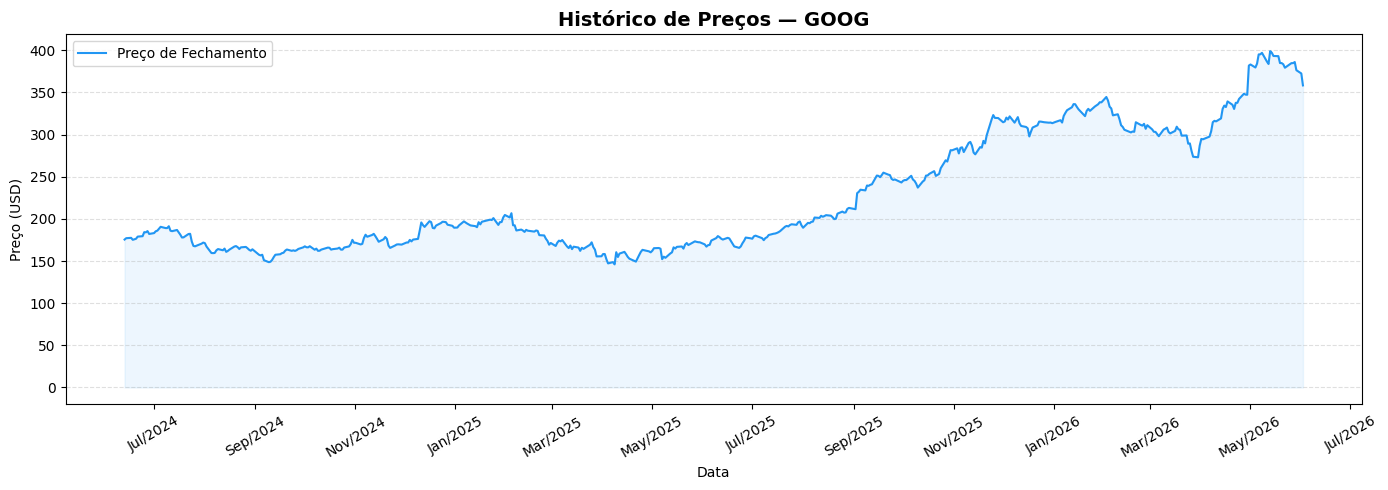

In [36]:
# ── Gráfico: preço de fechamento histórico ───────────────────────────────
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df_tcd_dados.index, df_tcd_dados['Close'],
        color='#2196F3', linewidth=1.5, label='Preço de Fechamento')
ax.fill_between(df_tcd_dados.index, df_tcd_dados['Close'],
                alpha=0.08, color='#2196F3')

ax.set_title(f'Histórico de Preços — {STOCK}', fontsize=14, fontweight='bold')
ax.set_xlabel('Data')
ax.set_ylabel('Preço (USD)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b/%Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.xticks(rotation=30)
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.legend()
plt.tight_layout()
plt.show()


---
## 5. Indicadores Técnicos <a id='5'></a>

Calculamos todos os indicadores de uma vez e armazenamos num DataFrame consolidado.

> **Nota:** usamos `.copy()` para não modificar o DataFrame original — bug comum em notebooks!


In [37]:
# ── Cópia segura (sem .copy() alteraria df_tcd_dados!) ───────────────────
df_indicadores = df_tcd_dados[['Close']].copy()

# ── 5.1 Bandas de Bollinger (janela=20, desvio=2 — padrão de mercado) ────
bb = BollingerBands(df_indicadores['Close'], window=20, window_dev=2)
df_indicadores['bb_media']  = bb.bollinger_mavg()   # Média móvel central
df_indicadores['bb_maximo'] = bb.bollinger_hband()  # Banda superior (+2σ)
df_indicadores['bb_minimo'] = bb.bollinger_lband()  # Banda inferior (-2σ)

# ── 5.2 MACD (12, 26, 9 — configuração padrão de mercado) ────────────────
macd_obj = MACD(df_indicadores['Close'], window_slow=26, window_fast=12, window_sign=9)
df_indicadores['macd']        = macd_obj.macd()
df_indicadores['macd_signal'] = macd_obj.macd_signal()
df_indicadores['macd_diff']   = macd_obj.macd_diff()  # Histograma

# ── 5.3 RSI (janela=14 — padrão de mercado) ──────────────────────────────
df_indicadores['rsi'] = RSIIndicator(df_indicadores['Close'], window=14).rsi()

# ── 5.4 SMA — Média Móvel Simples (janela=14) ─────────────────────────────
df_indicadores['sma_14'] = SMAIndicator(df_indicadores['Close'], window=14).sma_indicator()

# ── 5.5 EMA — Média Móvel Exponencial (janela=14) ─────────────────────────
df_indicadores['ema_14'] = EMAIndicator(df_indicadores['Close'], window=14).ema_indicator()

print(f'Indicadores calculados. Shape: {df_indicadores.shape}')
display(df_indicadores.tail(5).round(2))


Indicadores calculados. Shape: (493, 10)


,Close,bb_media,bb_maximo,bb_minimo,macd,macd_signal,macd_diff,rsi,sma_14,ema_14
Date,,,,,,,,,,
2026-05-27 00:00:00-04:00,384.83,385.97,407.49,364.45,11.35,14.91,-3.56,60.71,389.14,383.39
2026-05-28 00:00:00-04:00,386.12,387.91,400.13,375.69,10.64,14.06,-3.42,61.56,388.48,383.75
2026-05-29 00:00:00-04:00,376.43,387.64,400.61,374.67,9.19,13.09,-3.89,52.46,387.01,382.77
2026-06-01 00:00:00-04:00,372.58,387.10,401.54,372.66,7.64,12.00,-4.35,49.34,385.99,381.42
2026-06-02 00:00:00-04:00,358.39,386.04,404.96,367.13,5.21,10.64,-5.43,39.92,384.18,378.35


---
## 6. Visualizações com Matplotlib <a id='6'></a>

Cada indicador em painel dedicado com formatação profissional.


Os quatro painéis a seguir apresentam os **cinco indicadores técnicos** calculados na seção anterior. Cada um responde a uma pergunta diferente sobre o comportamento do ativo:

| Indicador | Pergunta que responde |
|-----------|----------------------|
| **Bandas de Bollinger** | O ativo está em região de sobrecompra ou sobrevenda pela volatilidade? |
| **MACD** | A tendência está ganhando ou perdendo força? Há cruzamento de sinal? |
| **RSI** | O momentum indica exaustão compradora ou vendedora? |
| **SMA vs EMA** | As médias móveis confirmam a tendência? EMA reage mais rápido? |


#### 📉 6.1 Bandas de Bollinger — Volatilidade e Extremos de Preço

As Bandas de Bollinger são compostas por **três linhas**:
- **Linha central (laranja tracejada):** SMA de 20 períodos — representa o preço médio recente
- **Banda superior (rosa pontilhada):** SMA + 2 desvios padrão — zona de sobrecompra potencial
- **Banda inferior (verde pontilhada):** SMA − 2 desvios padrão — zona de sobrevenda potencial

**Como interpretar:**

- Quando o preço **toca ou ultrapassa a banda superior** → o ativo pode estar sobrecomprado; atenção para possível reversão
- Quando o preço **toca ou rompe a banda inferior** → o ativo pode estar sobrevendido; possível oportunidade de entrada
- **Bandas se alargando** → aumento de volatilidade (mercado nervoso, tendência forte)
- **Bandas se estreitando (squeeze)** → baixa volatilidade; costuma preceder um movimento brusco de preço

> ⚠️ Bandas de Bollinger **não indicam direção** — apenas volatilidade. Combine sempre com MACD ou RSI para confirmar o sinal.


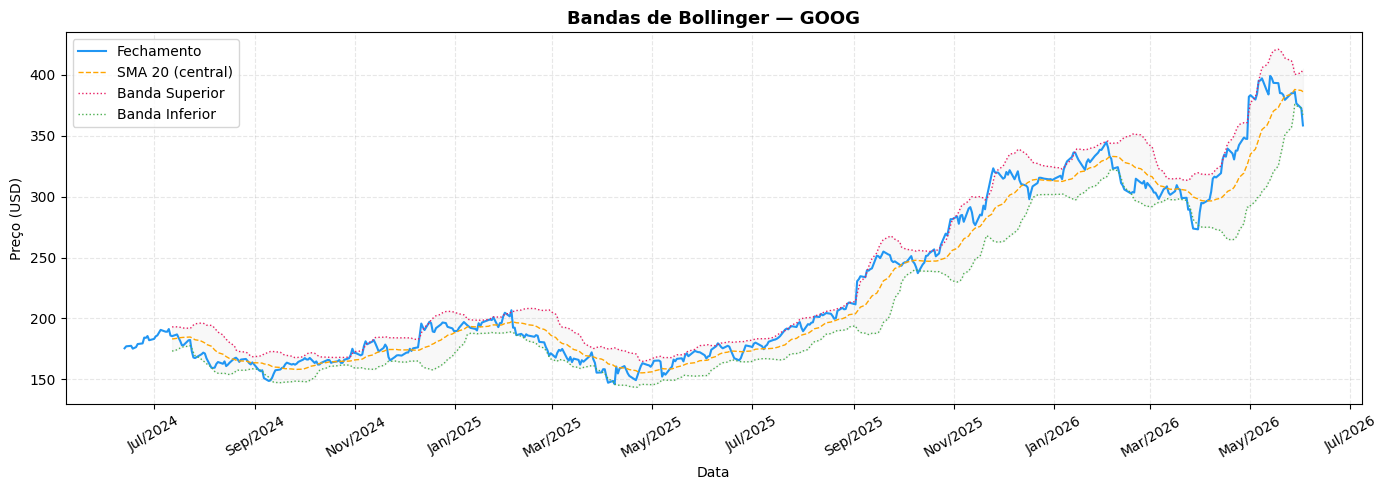

In [38]:
# ── 6.1 Bandas de Bollinger ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df_indicadores.index, df_indicadores['Close'],
        color='#2196F3', linewidth=1.5, label='Fechamento')
ax.plot(df_indicadores.index, df_indicadores['bb_media'],
        color='orange', linewidth=1, linestyle='--', label='SMA 20 (central)')
ax.plot(df_indicadores.index, df_indicadores['bb_maximo'],
        color='#E91E63', linewidth=1, linestyle=':', label='Banda Superior')
ax.plot(df_indicadores.index, df_indicadores['bb_minimo'],
        color='#4CAF50', linewidth=1, linestyle=':', label='Banda Inferior')
ax.fill_between(df_indicadores.index,
                df_indicadores['bb_maximo'], df_indicadores['bb_minimo'],
                alpha=0.05, color='gray')

ax.set_title(f'Bandas de Bollinger — {STOCK}', fontsize=13, fontweight='bold')
ax.set_xlabel('Data'); ax.set_ylabel('Preço (USD)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b/%Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.xticks(rotation=30); ax.grid(linestyle='--', alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()


#### 📈 6.2 MACD — Tendência e Momentum

O MACD é calculado como a diferença entre **EMA(12) e EMA(26)**, acompanhado de uma linha de sinal EMA(9) e um histograma.

**Como interpretar:**

- **MACD cruza acima da linha de sinal** (histograma positivo 🟢) → sinal de **compra** — momentum de alta ganhando força
- **MACD cruza abaixo da linha de sinal** (histograma negativo 🔴) → sinal de **venda** — momentum de baixa ganhando força
- **Histograma crescendo** → tendência atual se fortalecendo
- **Histograma encolhendo** → tendência perdendo força, possível reversão
- **Divergência:** preço faz novo topo mas MACD não acompanha → sinal de fraqueza na tendência de alta

> 💡 O painel superior mostra o preço de fechamento para você correlacionar visualmente os cruzamentos do MACD com os movimentos de preço.


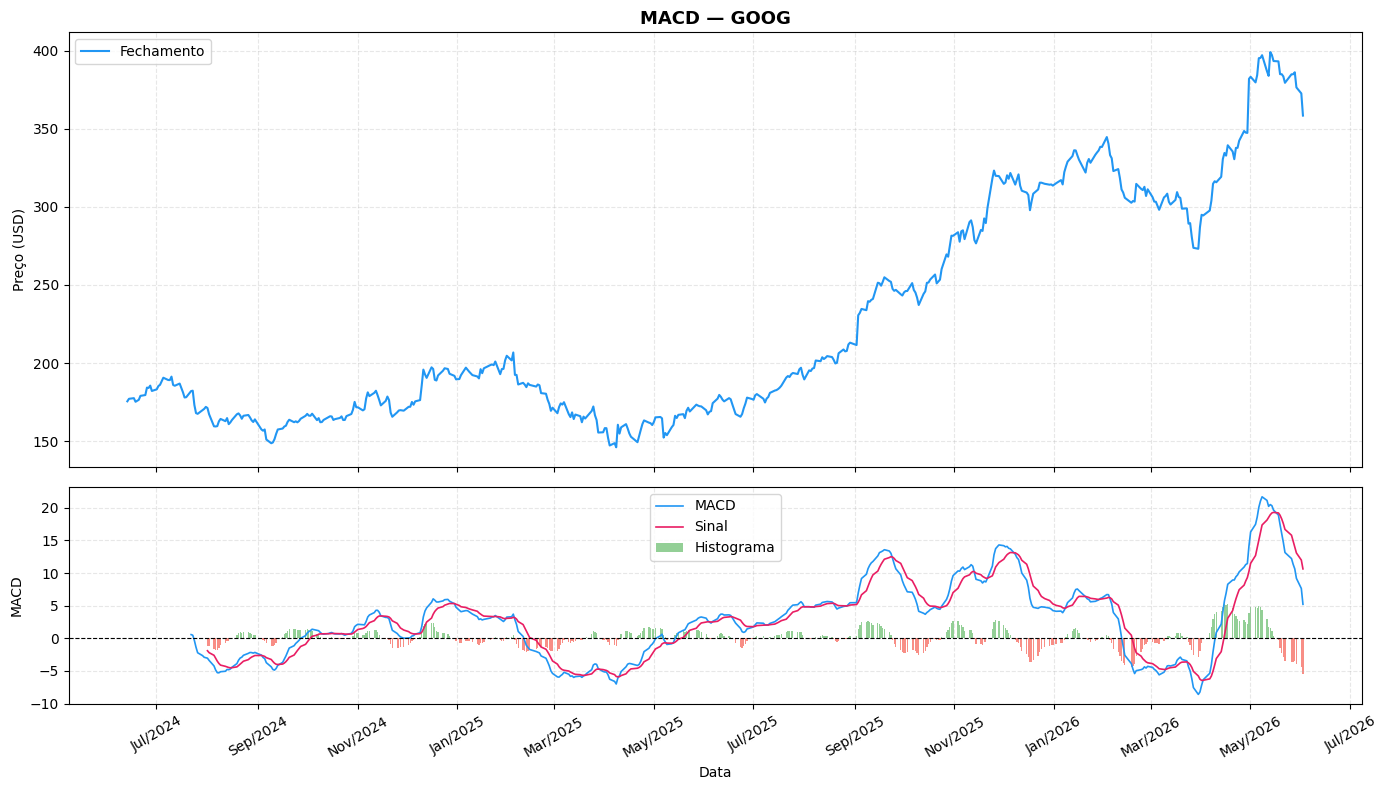

In [39]:
# ── 6.2 MACD (dois painéis) ──────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1]})

ax1.plot(df_indicadores.index, df_indicadores['Close'],
         color='#2196F3', linewidth=1.5, label='Fechamento')
ax1.set_title(f'MACD — {STOCK}', fontsize=13, fontweight='bold')
ax1.set_ylabel('Preço (USD)'); ax1.grid(linestyle='--', alpha=0.3); ax1.legend()

ax2.plot(df_indicadores.index, df_indicadores['macd'],
         color='#2196F3', linewidth=1.2, label='MACD')
ax2.plot(df_indicadores.index, df_indicadores['macd_signal'],
         color='#E91E63', linewidth=1.2, label='Sinal')

# Histograma colorido: verde se positivo, vermelho se negativo
colors = ['#4CAF50' if v >= 0 else '#F44336'
          for v in df_indicadores['macd_diff'].fillna(0)]
ax2.bar(df_indicadores.index, df_indicadores['macd_diff'],
        color=colors, alpha=0.6, label='Histograma')
ax2.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax2.set_ylabel('MACD'); ax2.set_xlabel('Data')
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b/%Y'))
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.xticks(rotation=30); ax2.grid(linestyle='--', alpha=0.3); ax2.legend()
plt.tight_layout(); plt.show()


#### ⚡ 6.3 RSI — Índice de Força Relativa

O RSI mede a **velocidade e magnitude** das variações de preço numa escala de 0 a 100, usando uma janela padrão de 14 períodos.

**Zonas de referência:**

| Faixa RSI | Interpretação | Ação típica |
|-----------|--------------|-------------|
| **> 70** | Sobrecompra (linha vermelha) | Atenção para possível correção |
| **50 – 70** | Território comprador | Tendência de alta moderada |
| **30 – 50** | Território vendedor | Tendência de baixa moderada |
| **< 30** | Sobrevenda (linha verde) | Possível oportunidade de entrada |

**Sinais adicionais:**

- **RSI divergindo do preço:** preço sobe mas RSI cai → fraqueza oculta na tendência
- **RSI cruzando a linha dos 50** → mudança de regime (comprador ↔ vendedor)

> ⚠️ Em tendências muito fortes, o RSI pode permanecer em zona de sobrecompra/sobrevenda por longos períodos sem reversão imediata.


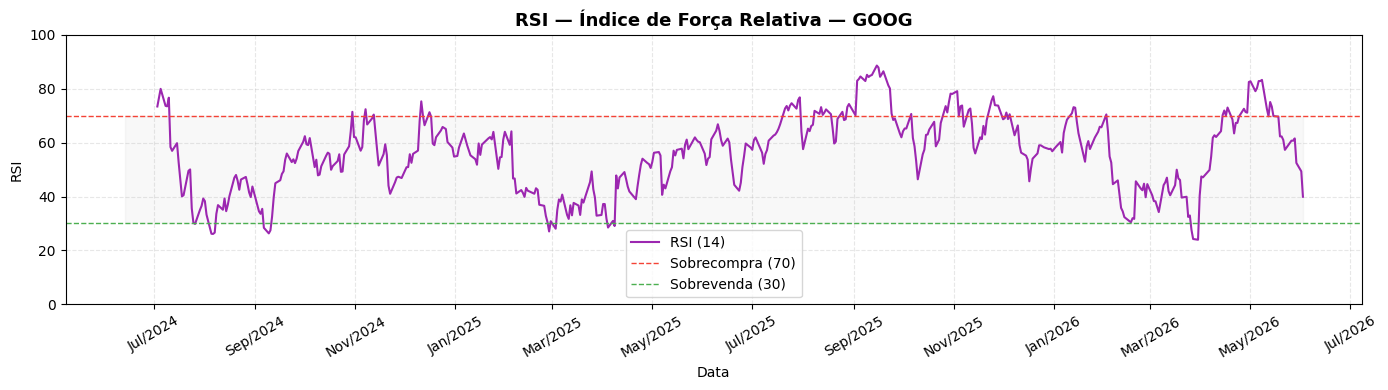

In [40]:
# ── 6.3 RSI com zonas de referência ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 4))

ax.plot(df_indicadores.index, df_indicadores['rsi'],
        color='#9C27B0', linewidth=1.5, label='RSI (14)')
ax.axhline(70, color='#F44336', linestyle='--', linewidth=1, label='Sobrecompra (70)')
ax.axhline(30, color='#4CAF50', linestyle='--', linewidth=1, label='Sobrevenda (30)')
ax.fill_between(df_indicadores.index, 30, 70, alpha=0.05, color='gray')

ax.set_title(f'RSI — Índice de Força Relativa — {STOCK}', fontsize=13, fontweight='bold')
ax.set_xlabel('Data'); ax.set_ylabel('RSI'); ax.set_ylim(0, 100)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b/%Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.xticks(rotation=30); ax.grid(linestyle='--', alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()


#### 〰️ 6.4 SMA vs EMA — Médias Móveis Comparadas

Ambas as médias suavizam o ruído do preço, mas com velocidades diferentes:

| Indicador | Característica | Melhor uso |
|-----------|---------------|------------|
| **SMA 14** (laranja) | Pesos iguais para todos os 14 períodos | Tendências de médio prazo |
| **EMA 14** (verde tracejado) | Mais peso nos preços recentes | Reações rápidas, curto prazo |

**Como interpretar:**

- **Preço acima de ambas as médias** → tendência de alta confirmada
- **Preço abaixo de ambas as médias** → tendência de baixa confirmada
- **EMA cruzando acima da SMA** → sinal de aceleração de alta (golden cross)
- **EMA cruzando abaixo da SMA** → sinal de aceleração de baixa (death cross)
- **Quanto maior a distância entre preço e médias** → maior o risco de correção

> 💡 Note como a EMA (verde) **reage mais rápido** às mudanças de preço do que a SMA (laranja) — isso é visível especialmente em movimentos bruscos.


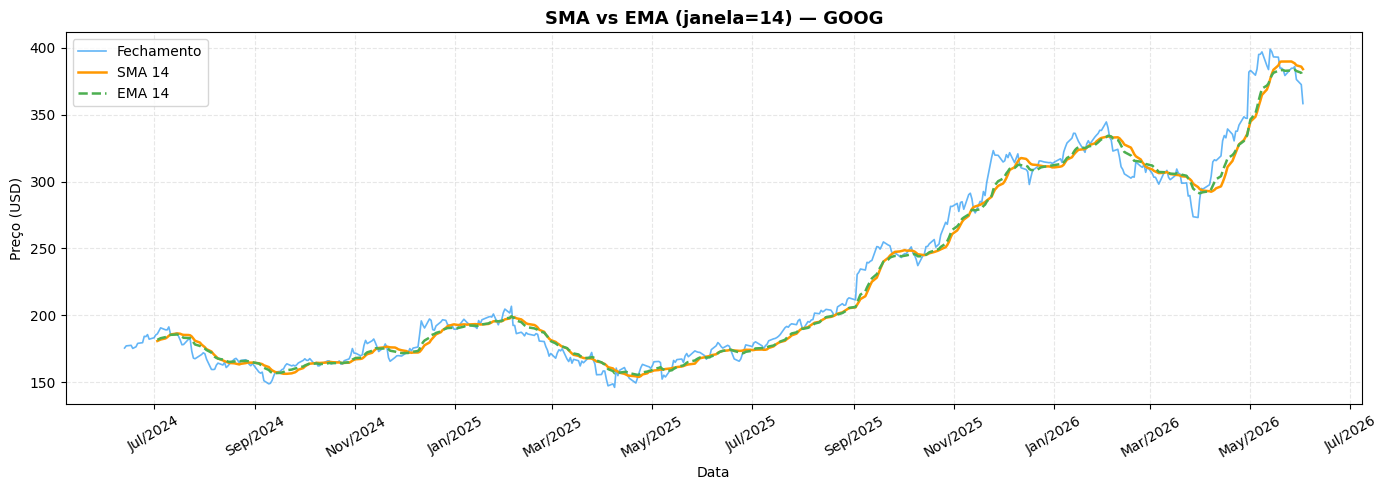

In [41]:
# ── 6.4 SMA vs EMA ───────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df_indicadores.index, df_indicadores['Close'],
        color='#2196F3', linewidth=1.2, alpha=0.7, label='Fechamento')
ax.plot(df_indicadores.index, df_indicadores['sma_14'],
        color='#FF9800', linewidth=1.8, label='SMA 14')
ax.plot(df_indicadores.index, df_indicadores['ema_14'],
        color='#4CAF50', linewidth=1.8, linestyle='--', label='EMA 14')

ax.set_title(f'SMA vs EMA (janela=14) — {STOCK}', fontsize=13, fontweight='bold')
ax.set_xlabel('Data'); ax.set_ylabel('Preço (USD)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b/%Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.xticks(rotation=30); ax.grid(linestyle='--', alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()


---
## 7. Modelo Preditivo — Regressão Linear <a id='7'></a>

A estratégia usa **shift temporal**: a variável-alvo é o preço `N` dias à frente.

> **Limitação:** Regressão Linear em séries temporais financeiras é uma abordagem baseline educacional. Não constitui recomendação de investimento.


In [42]:
def tcd_gerando_previsoes(df_dados: pd.DataFrame, num_dias: int = 5) -> dict:
    """
    Treina Regressão Linear para prever preço de fechamento.

    Parâmetros
    ----------
    df_dados : pd.DataFrame  — DataFrame com coluna 'Close'.
    num_dias : int           — Horizonte de previsão em dias de pregão.

    Retorna
    -------
    dict : modelo, r2, mae, previsoes, datas_previstas (tz-naive)
    """
    df = df_dados[['Close']].copy()

    # Variável-alvo: preço N dias à frente
    df['target'] = df['Close'].shift(-num_dias)

    # Remove NaN gerados pelo shift
    x = df[['Close']].values[:-num_dias]
    y = df['target'].values[:-num_dias]

    # Divisão treino/teste (80/20)
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, random_state=42
    )

    # Padronização: fit SOMENTE no treino para evitar data leakage
    scaler = StandardScaler()
    x_train_sc = scaler.fit_transform(x_train)
    x_test_sc  = scaler.transform(x_test)

    # Treino
    modelo = LinearRegression()
    modelo.fit(x_train_sc, y_train)

    # Avaliação
    y_pred = modelo.predict(x_test_sc)
    r2  = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)

    # Previsão dos próximos N dias
    x_forecast    = df[['Close']].values[-num_dias:]
    x_forecast_sc = scaler.transform(x_forecast)
    previsoes     = modelo.predict(x_forecast_sc)

    # ── Normaliza o último dia para tz-naive ────────────────────────────
    # O índice do yfinance vem com timezone (ex.: America/New_York).
    # pd.bdate_range gera datas tz-naive — precisamos do mesmo padrão.
    ultimo_ts = df_dados.index[-1]
    if hasattr(ultimo_ts, 'tz') and ultimo_ts.tz is not None:
        ultimo_ts = ultimo_ts.tz_convert('UTC').tz_localize(None)
    ultimo_dia = ultimo_ts.date() if hasattr(ultimo_ts, 'date') else ultimo_ts

    datas_futuras = pd.bdate_range(start=ultimo_dia, periods=num_dias + 1)[1:]

    return {
        'modelo': modelo,
        'r2': r2,
        'mae': mae,
        'previsoes': previsoes,
        'datas_previstas': datas_futuras,  # sempre tz-naive
    }


---
## 8. Métricas e Gráfico de Previsão <a id='8'></a>

### Como avaliar o modelo

Utilizamos duas métricas para avaliar a qualidade das previsões no conjunto de teste (20% dos dados):

| Métrica | O que mede | Como interpretar |
|---------|-----------|------------------|
| **R² (R-squared)** | Proporção da variância do preço explicada pelo modelo | Próximo de 1.0 → excelente; < 0.5 → fraco |
| **MAE (Mean Absolute Error)** | Erro médio absoluto em dólares | Quanto menor, melhor; indica o desvio típico das previsões |

### Interpretando o gráfico de previsão

- A **linha azul** mostra os últimos 60 dias de preço real (histórico)
- A **linha laranja tracejada** mostra os preços previstos para os próximos N dias úteis
- A **linha cinza pontilhada vertical** marca a fronteira entre passado e futuro
- Os pontos circulares na linha de previsão representam cada dia de pregão previsto

> ⚠️ **Limitação importante:** o modelo usa apenas o preço de fechamento como feature. Preços reais são influenciados por volume, notícias, macro e sentimento — fatores não capturados aqui. Trate as previsões como **referência educacional**, não como sinal de trading.


In [43]:
# ── Configuração do horizonte de previsão ────────────────────────────────
NUM_DIAS_PREVISAO = 5  # Altere para o horizonte desejado

resultado = tcd_gerando_previsoes(df_tcd_dados, num_dias=NUM_DIAS_PREVISAO)

print('=' * 45)
print('MÉTRICAS DO MODELO')
print('=' * 45)
print(f"R2  (variância explicada): {resultado['r2']:.4f}")
print(f"MAE (erro médio em USD):  $ {resultado['mae']:.2f}")
print('=' * 45)
print(f"\nPREVISOES — próximos {NUM_DIAS_PREVISAO} dias de pregao:")
print('-' * 45)
for data, valor in zip(resultado['datas_previstas'], resultado['previsoes']):
    print(f"  {data.strftime('%d/%m/%Y')}  ->  US$ {valor:.2f}")


MÉTRICAS DO MODELO
R2  (variância explicada): 0.9836
MAE (erro médio em USD):  $ 7.19

PREVISOES — próximos 5 dias de pregao:
---------------------------------------------
  03/06/2026  ->  US$ 390.79
  04/06/2026  ->  US$ 392.10
  05/06/2026  ->  US$ 382.22
  08/06/2026  ->  US$ 378.29
  09/06/2026  ->  US$ 363.81


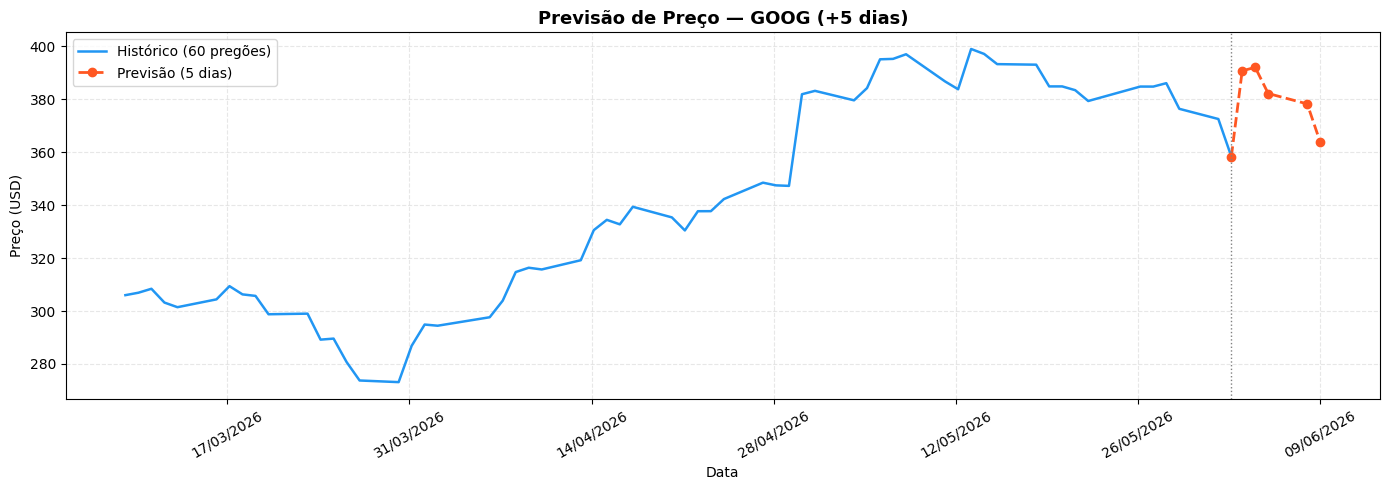

In [44]:
# ── Gráfico: histórico recente + previsão ────────────────────────────────
historico_recente = df_tcd_dados[['Close']].tail(60).copy()

# ── Correção de timezone ─────────────────────────────────────────────────
# O índice do yfinance vem com tz (ex.: America/New_York); pd.bdate_range
# gera datas tz-naive. Matplotlib não mistura os dois — normalizamos tudo
# para tz-naive (UTC) antes de plotar.
if historico_recente.index.tz is not None:
    historico_recente.index = historico_recente.index.tz_convert('UTC').tz_localize(None)

ultimo_ponto_hist = historico_recente.index[-1]  # já tz-naive

# Converte as datas previstas para tz-naive também
datas_futuras_naive = pd.DatetimeIndex(resultado['datas_previstas']).tz_localize(None)

# Conecta o último ponto histórico ao início da previsão
datas_plot   = [ultimo_ponto_hist] + list(datas_futuras_naive)
valores_plot = [historico_recente['Close'].iloc[-1]] + list(resultado['previsoes'])

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(historico_recente.index, historico_recente['Close'],
        color='#2196F3', linewidth=1.8, label='Histórico (60 pregões)')

ax.plot(datas_plot, valores_plot,
        color='#FF5722', linewidth=2, linestyle='--',
        marker='o', markersize=6, label=f'Previsão ({NUM_DIAS_PREVISAO} dias)')

ax.axvline(ultimo_ponto_hist, color='gray', linestyle=':', linewidth=1)
ax.set_title(f'Previsão de Preço — {STOCK} (+{NUM_DIAS_PREVISAO} dias)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Data'); ax.set_ylabel('Preço (USD)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m/%Y'))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
plt.xticks(rotation=30); ax.grid(linestyle='--', alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()


---
## 9. Conclusão <a id='9'></a>

### ✅ O que foi desenvolvido

| Etapa | Ferramenta | Resultado |
|-------|-----------|----------|
| Coleta de dados | `yfinance` | Download automático com validação de dados vazios |
| Indicadores técnicos | `ta` | Bollinger, MACD, RSI, SMA e EMA calculados e consolidados |
| Visualizações | `matplotlib` | 5 painéis com formatação profissional e zonas de referência |
| Modelo preditivo | `scikit-learn` | Regressão Linear com padronização e split treino/teste |
| Aplicação web | `streamlit` | Interface interativa disponível em `app.py` |

### 📊 Síntese dos Indicadores

| Indicador | Sinal de Alta | Sinal de Baixa |
|-----------|-------------|----------------|
| **Bollinger** | Preço na banda inferior (sobrevenda) | Preço na banda superior (sobrecompra) |
| **MACD** | MACD cruza acima do sinal | MACD cruza abaixo do sinal |
| **RSI** | RSI < 30 (sobrevenda) | RSI > 70 (sobrecompra) |
| **SMA/EMA** | Preço acima das médias | Preço abaixo das médias |

### ⚠️ Limitações do Modelo Atual

- **Feature única:** usa apenas o preço de fechamento — ignora Volume, notícias e macro
- **Linearidade:** mercados financeiros têm comportamento não-linear — Regressão Linear é um baseline
- **Lookahead bias:** o shift temporal assume que dados futuros são previsíveis a partir do passado imediato
- **Sem validação temporal:** o `train_test_split` aleatório pode misturar dados de períodos diferentes

### 🚀 Próximos Passos Recomendados

1. **Melhorar o modelo:** substituir por LSTM, Prophet ou XGBoost com múltiplas features
2. **Validação temporal:** usar `TimeSeriesSplit` do scikit-learn em vez de split aleatório
3. **Mais features:** Volume, todos os indicadores calculados (RSI, MACD, BB) como variáveis preditoras
4. **Alertas:** criar notificações automáticas quando RSI > 70 ou < 30
5. **Mais ativos:** expandir para BDRs, criptomoedas e índices (IBOVESPA, S&P 500)

---
*Nerd dos Dados — Método TCD | Projeto 8*
